=== Checking data for all mice ===
Mouse 0: exists=True | path=./result_new/mouse_0/stage_0/dynamic_full_graphs.npy
  → shape = (2401, 13, 13)
Mouse 1: exists=True | path=./result_new/mouse_1/stage_0/dynamic_full_graphs.npy
  → shape = (2401, 13, 13)
Mouse 2: exists=True | path=./result_new/mouse_2/stage_0/dynamic_full_graphs.npy
  → shape = (2401, 13, 13)
Mouse 3: exists=True | path=./result_new/mouse_3/stage_0/dynamic_full_graphs.npy
  → shape = (2401, 13, 13)
Mouse 4: exists=True | path=./result_new/mouse_4/stage_0/dynamic_full_graphs.npy
  → shape = (2401, 13, 13)

=== All data successfully loaded ===



/tmp/ipykernel_1028583/2750874010.py:39: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(vals, label=f"Mouse {m}", fill=False, palette="Paired")
/tmp/ipykernel_1028583/2750874010.py:39: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(vals, label=f"Mouse {m}", fill=False, palette="Paired")
/tmp/ipykernel_1028583/2750874010.py:39: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(vals, label=f"Mouse {m}", fill=False, palette="Paired")
/tmp/ipykernel_1028583/2750874010.py:39: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(vals, label=f"Mouse {m}", fill=False, palette="Paired")
/tmp/ipykernel_1028583/2750874010.py:39: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(vals, label=f"Mouse {m}", fill=False, palette="Paired")


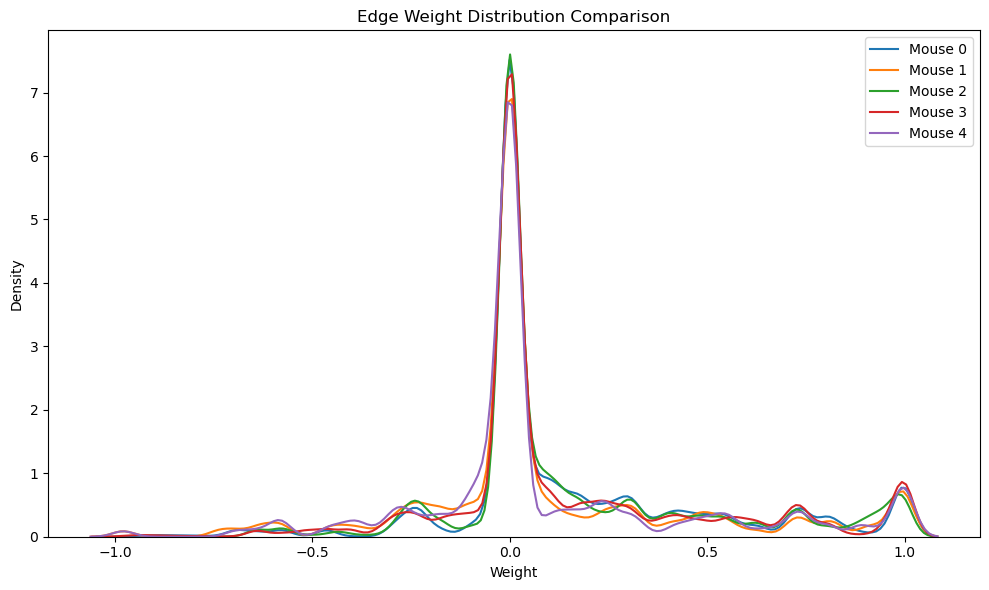

Mouse 0: Excitatory=0.426, Inhibitory=0.101
Mouse 1: Excitatory=0.325, Inhibitory=0.201
Mouse 2: Excitatory=0.423, Inhibitory=0.104
Mouse 3: Excitatory=0.392, Inhibitory=0.135
Mouse 4: Excitatory=0.302, Inhibitory=0.225


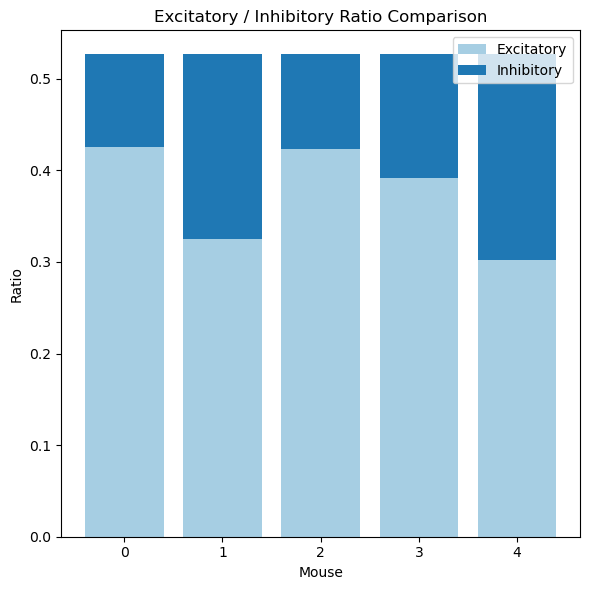

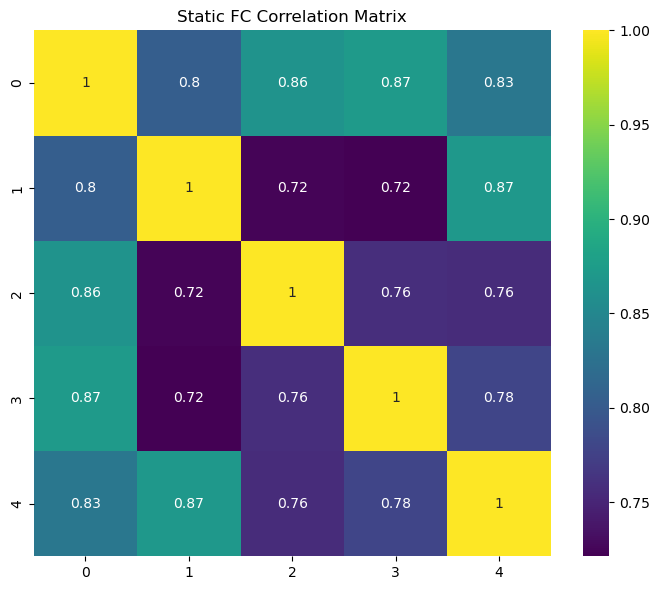

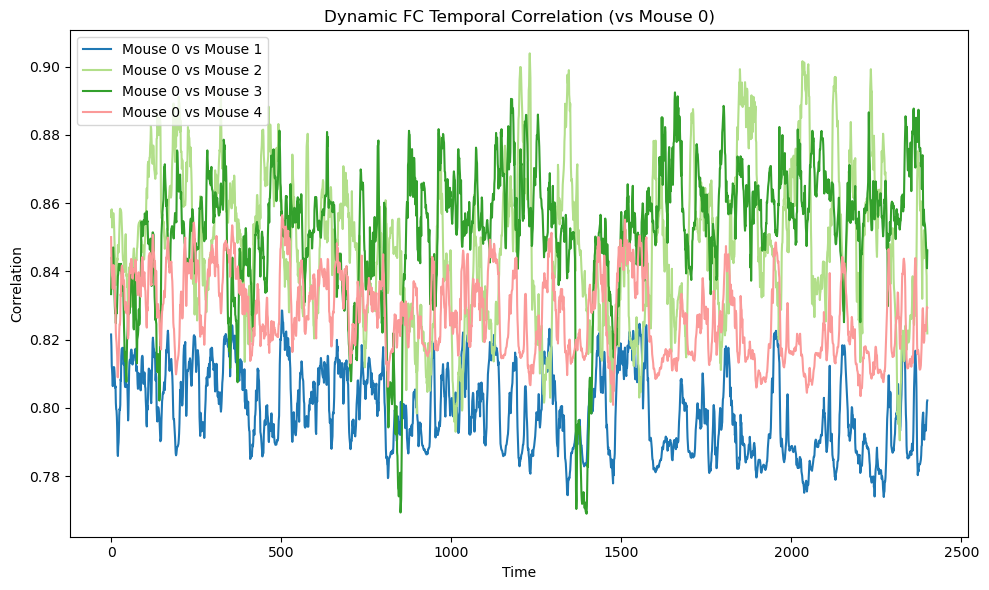

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
from scipy.stats import pearsonr
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import umap.umap_ as umap

mouse_ids = [0, 1, 2, 3, 4]
base_path = "./result_new"
stage = "stage_0"

data_dict = {}

print("=== Checking data for all mice ===")
for m in mouse_ids:
    file_path = f"{base_path}/mouse_{m}/{stage}/dynamic_full_graphs.npy"
    exists = os.path.exists(file_path)
    print(f"Mouse {m}: exists={exists} | path={file_path}")

    if not exists:
        raise FileNotFoundError(f"File not found: mouse_{m}/dynamic_full_graphs.npy")

    arr = np.load(file_path)
    print(f"  → shape = {arr.shape}")

    if arr.shape[0] < 100:
        print(f"Warning: mouse_{m} has too few time points (T={arr.shape[0]}).")

    data_dict[m] = arr

print("\n=== All data successfully loaded ===\n")

plt.figure(figsize=(10, 6))
for m in data_dict:
    vals = data_dict[m].flatten()
    sns.kdeplot(vals, label=f"Mouse {m}", fill=False, palette="Paired")
plt.title("Edge Weight Distribution Comparison")
plt.xlabel("Weight")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.savefig("Edge_Weight_Distribution.pdf", format="pdf")
plt.show()

def compute_exc_inh_ratio(data):
    vals = data.flatten()
    n = len(vals)
    exc = np.sum(vals > 0)
    inh = np.sum(vals < 0)
    return exc/n, inh/n

ratios = []
for m in mouse_ids:
    exc, inh = compute_exc_inh_ratio(data_dict[m])
    ratios.append([exc, inh])
    print(f"Mouse {m}: Excitatory={exc:.3f}, Inhibitory={inh:.3f}")

plt.figure(figsize=(6,6))
ratios = np.array(ratios)
plt.bar(mouse_ids, ratios[:,0], label="Excitatory", color=sns.color_palette("Paired")[0])
plt.bar(mouse_ids, ratios[:,1], bottom=ratios[:,0], label="Inhibitory", color=sns.color_palette("Paired")[1])
plt.ylabel("Ratio")
plt.xlabel("Mouse")
plt.title("Excitatory / Inhibitory Ratio Comparison")
plt.legend()
plt.tight_layout()
plt.savefig("Excitatory_Inhibitory Ratio Comparison.pdf", format="pdf")
plt.show()

static_dict = {m: np.mean(data_dict[m], axis=0) for m in mouse_ids}

corr_matrix = np.zeros((5, 5))
for i, m1 in enumerate(mouse_ids):
    for j, m2 in enumerate(mouse_ids):
        v1 = static_dict[m1].flatten()
        v2 = static_dict[m2].flatten()
        corr_matrix[i, j] = pearsonr(v1, v2)[0]

plt.figure(figsize=(7,6))
sns.heatmap(corr_matrix, annot=True, cmap="viridis",
            xticklabels=mouse_ids, yticklabels=mouse_ids)
plt.title("Static FC Correlation Matrix")
plt.tight_layout()
plt.savefig("Static_FC_Correlation_Matrix.pdf", format="pdf")
plt.show()

def compute_dynamic_correlation(data1, data2):
    T = min(data1.shape[0], data2.shape[0])
    corr_list = []
    for t in range(T):
        v1 = data1[t].flatten()
        v2 = data2[t].flatten()
        corr = pearsonr(v1, v2)[0]
        corr_list.append(corr)
    return corr_list

plt.figure(figsize=(10,6))
palette = sns.color_palette("Paired", n_colors=5)

for idx, m in enumerate(mouse_ids[1:]):
    corr_list = compute_dynamic_correlation(data_dict[0], data_dict[m])
    plt.plot(corr_list, label=f"Mouse 0 vs Mouse {m}", color=palette[m])

plt.xlabel("Time")
plt.ylabel("Correlation")
plt.title("Dynamic FC Temporal Correlation (vs Mouse 0)")
plt.legend()
plt.tight_layout()
plt.savefig("Dynamic_FC_Temporal_Correlation.pdf", format="pdf")
plt.show()

Total timepoints (all mice): 12005


/home/ylx/anaconda3/envs/ibl_bwm/lib/python3.10/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Silhouette Coefficient: 0.751


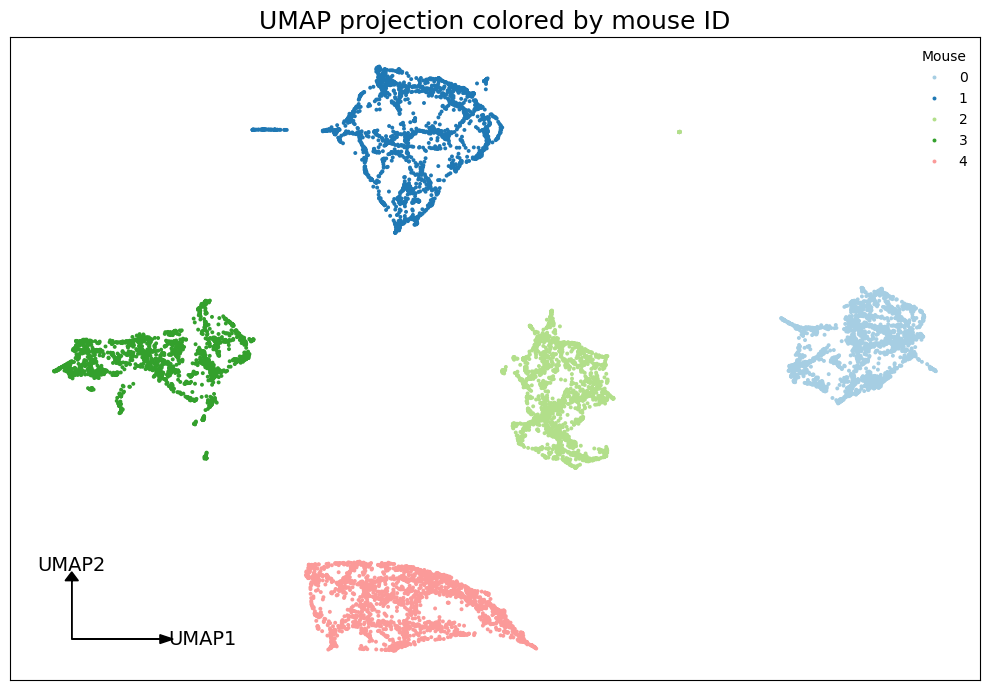

In [2]:
all_vectors = []
all_mouse_ids = [] 

for m in mouse_ids:
    T = data_dict[m].shape[0]
    for t in range(T):
        all_vectors.append(data_dict[m][t].flatten())
        all_mouse_ids.append(m)

all_vectors = np.array(all_vectors)
all_mouse_ids = np.array(all_mouse_ids)

print("Total timepoints (all mice):", all_vectors.shape[0])

scaler = StandardScaler()
X = scaler.fit_transform(all_vectors)

# UMAP
reducer = umap.UMAP(n_neighbors=40, min_dist=0.05, random_state=0)
X_umap = reducer.fit_transform(X)

from sklearn.metrics import silhouette_score
score = silhouette_score(X_umap, all_mouse_ids)
print(f"Silhouette Coefficient: {score:.3f}")

plt.figure(figsize=(10,7))

sns.scatterplot(
    x=X_umap[:,0],
    y=X_umap[:,1],
    hue=all_mouse_ids,
    palette="Paired",
    s=8,
    linewidth=0
)

plt.legend(title="Mouse", frameon=False)

plt.xticks([])
plt.yticks([])
plt.xlabel("")
plt.ylabel("")

ax = plt.gca()

dx = (X_umap[:,0].max() - X_umap[:,0].min()) * 0.1
dy = (X_umap[:,1].max() - X_umap[:,1].min()) * 0.1

start_x = X_umap[:,0].min() + dx * 0.2
start_y = X_umap[:,1].min() + dy * 0.2

ax.arrow(start_x, start_y, dx, 0,
         head_width=dy*0.15, head_length=dx*0.15,
         fc='black', ec='black', linewidth=1)

ax.arrow(start_x, start_y, 0, dy,
         head_width=dx*0.15, head_length=dy*0.15,
         fc='black', ec='black', linewidth=1)

plt.text(start_x + dx*1.1, start_y, "UMAP1", fontsize=14, ha='left', va='center')
plt.text(start_x, start_y + dy*1.1, "UMAP2", fontsize=14, ha='center', va='bottom')

plt.title("UMAP projection colored by mouse ID", fontsize=18)

plt.tight_layout()
plt.savefig("UMAP_dFC.pdf", format="pdf")
plt.show()


Bootstrap...


100%|██████████| 1000/1000 [13:12<00:00,  1.26it/s]


Bootstrap silhouette: 0.751 ± 0.001


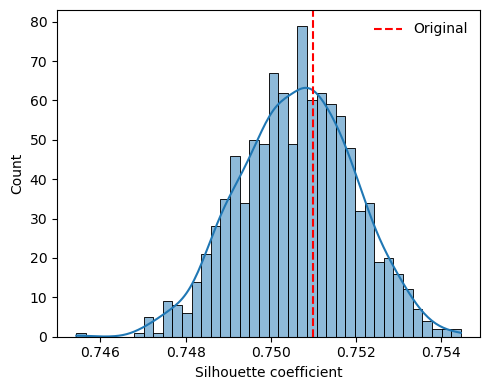

Permutation...


100%|██████████| 1000/1000 [19:52<00:00,  1.19s/it]


Observed PCA silhouette: 0.672
Permutation p-value: 0.00100


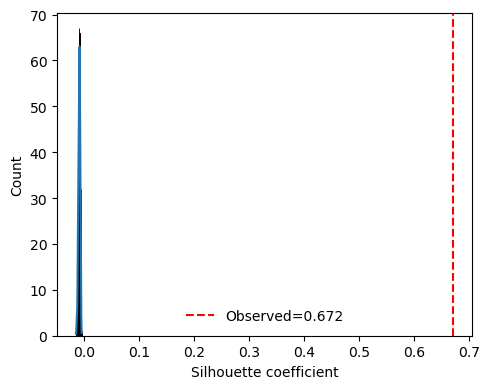

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

n_boot,n_perm,ratio=1000,1000,0.8

print("Bootstrap...")
boot=[]
N=len(all_mouse_ids)

for _ in tqdm(range(n_boot)):
    idx=np.random.choice(N,int(N*ratio),replace=True)
    boot.append(silhouette_score(X_umap[idx],all_mouse_ids[idx]))

boot=np.array(boot)
print(f"Bootstrap silhouette: {boot.mean():.3f} ± {boot.std():.3f}")

plt.figure(figsize=(5,4))
sns.histplot(boot,bins=40,kde=True)
plt.axvline(0.751,color="r",ls="--",label="Original")
plt.xlabel("Silhouette coefficient")
plt.legend(frameon=False)
plt.tight_layout()
plt.savefig("temporal_bootstrap_silhouette.pdf",dpi=600)
plt.show()


print("Permutation...")
X=PCA(n_components=20,random_state=0).fit_transform(
    StandardScaler().fit_transform(all_vectors)
)

obs=silhouette_score(X,all_mouse_ids)

perm=[]
for _ in tqdm(range(n_perm)):
    perm.append(
        silhouette_score(
            X,
            np.random.permutation(all_mouse_ids)
        )
    )

perm=np.array(perm)
p=(np.sum(perm>=obs)+1)/(n_perm+1)

print(f"Observed PCA silhouette: {obs:.3f}")
print(f"Permutation p-value: {p:.5f}")

plt.figure(figsize=(5,4))
sns.histplot(perm,bins=40,kde=True)
plt.axvline(obs,color="r",ls="--",label=f"Observed={obs:.3f}")
plt.xlabel("Silhouette coefficient")
plt.legend(frameon=False)
plt.tight_layout()
plt.savefig("permutation_null_silhouette.pdf",dpi=600)
plt.show()

Permutation: 100%|██████████| 1000/1000 [00:00<00:00, 1312.53it/s]


Samples: 100
Observed PCA silhouette: 0.676
Null: -0.081 ± 0.006
Permutation p-value: 0.00100


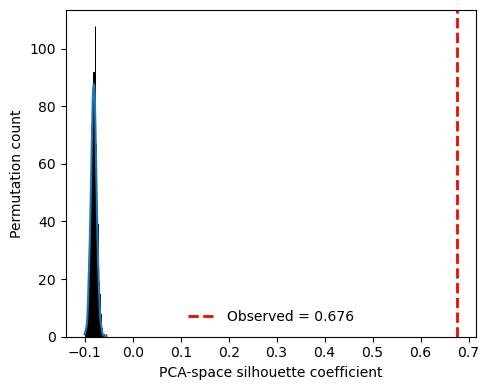

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

n_blocks,n_perm,n_pc=20,1000,20
X,y=[],[]

for m in mouse_ids:
    a=data_dict[m]
    for idx in np.array_split(np.arange(a.shape[0]),n_blocks):
        if len(idx):
            X.append(a[idx].mean(0).ravel())
            y.append(m)

X=np.asarray(X)
y=np.asarray(y)
X=PCA(n_components=min(n_pc,X.shape[0]-1,X.shape[1]),random_state=0).fit_transform(
    StandardScaler().fit_transform(X)
)

obs=silhouette_score(X,y)
null=np.array([
    silhouette_score(X,np.random.permutation(y))
    for _ in tqdm(range(n_perm),desc="Permutation")
])
p=(np.sum(null>=obs)+1)/(n_perm+1)

print(f"Samples: {len(y)}")
print(f"Observed PCA silhouette: {obs:.3f}")
print(f"Null: {null.mean():.3f} ± {null.std():.3f}")
print(f"Permutation p-value: {p:.5f}")

plt.figure(figsize=(5,4))
sns.histplot(null,bins=35,kde=True)
plt.axvline(obs,color="r",ls="--",lw=2,label=f"Observed = {obs:.3f}")
plt.xlabel("PCA-space silhouette coefficient")
plt.ylabel("Permutation count")
plt.legend(frameon=False)
plt.tight_layout()
plt.savefig("PCA_block_permutation_silhouette.pdf",dpi=600,bbox_inches="tight")
plt.show()

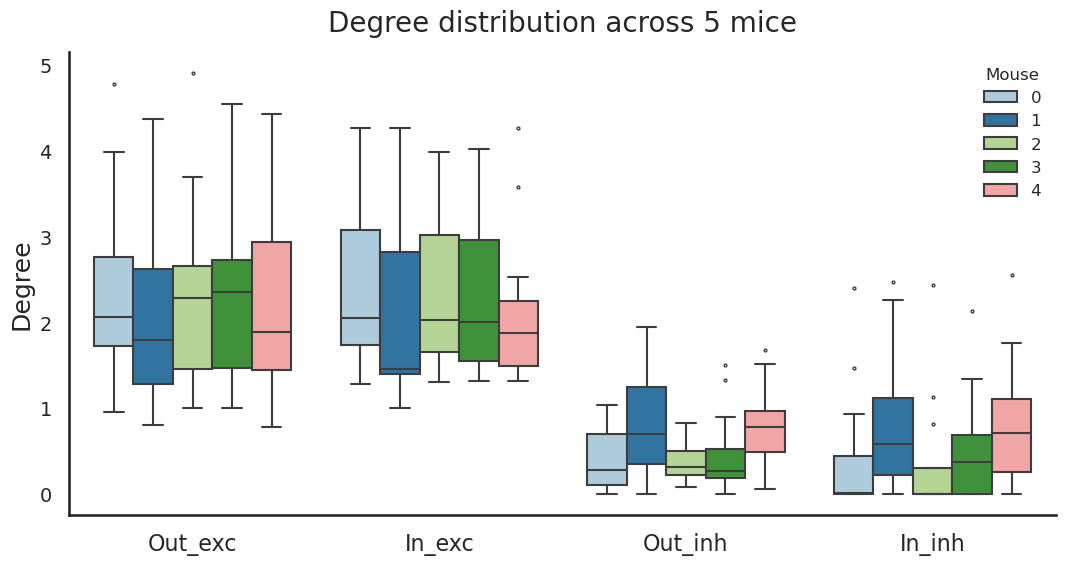

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def degree_by_node(A, mode="exc"):
    if mode == "exc":
        A = np.where(A > 0, A, 0)
    else:
        A = np.where(A < 0, -A, 0)

    out_deg = np.sum(A, axis=1)
    in_deg  = np.sum(A, axis=0)
    return out_deg, in_deg


out_exc_all_mice = []
in_exc_all_mice = []
out_inh_all_mice = []
in_inh_all_mice = []

for m in range(5):
    mouse = data_dict[m]

    all_out_exc, all_in_exc = [], []
    all_out_inh, all_in_inh = [], []

    for t in range(mouse.shape[0]):
        A = mouse[t]
        oe, ie = degree_by_node(A, "exc")
        oi, ii = degree_by_node(A, "inh")

        all_out_exc.append(oe)
        all_in_exc.append(ie)
        all_out_inh.append(oi)
        all_in_inh.append(ii)

    out_exc_node = np.mean(all_out_exc, axis=0)
    in_exc_node  = np.mean(all_in_exc, axis=0)
    out_inh_node = np.mean(all_out_inh, axis=0)
    in_inh_node  = np.mean(all_in_inh, axis=0)

    out_exc_all_mice.append(out_exc_node)
    in_exc_all_mice.append(in_exc_node)
    out_inh_all_mice.append(out_inh_node)
    in_inh_all_mice.append(in_inh_node)

plot_data = []

for m in range(5):
    for val in out_exc_all_mice[m]:
        plot_data.append(["Out_exc", m, val])
    for val in in_exc_all_mice[m]:
        plot_data.append(["In_exc", m, val])
    for val in out_inh_all_mice[m]:
        plot_data.append(["Out_inh", m, val])
    for val in in_inh_all_mice[m]:
        plot_data.append(["In_inh", m, val])

import pandas as pd
df = pd.DataFrame(plot_data, columns=["DegreeType", "Mouse", "Value"])


import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set(style="white", context="talk")

plt.figure(figsize=(11,6))

sns.boxplot(
    data=df,
    x="DegreeType",
    y="Value",
    hue="Mouse",
    palette="Paired",
    linewidth=1.5,
    fliersize=2
)

plt.xlabel("")
plt.ylabel("Degree", fontsize=18)

plt.title("Degree distribution across 5 mice", fontsize=20, pad=15)

plt.xticks(fontsize=16)
plt.yticks(fontsize=14)

sns.despine(top=True, right=True)

plt.legend(title="Mouse", fontsize=12, title_fontsize=12, frameon=False, loc="upper right")

plt.tight_layout()
plt.savefig("Degree_distribution.pdf", format="pdf")
plt.show()

In [7]:
from scipy.stats import kruskal
import scikit_posthocs as sp
import numpy as np

def print_significance_test(data_list, label):

    print("\n==============================")
    print(f"Significance test for {label}")
    print("==============================")

    # Kruskal-Wallis multi-group compairation
    stat, p = kruskal(*data_list)
    print(f"Kruskal-Wallis H-test: H={stat:.3f}, p={p:.3e}")

    if p < 0.05:
        print("→ 🟥 Significant difference! (At least two mice are different)")
        print("→ Perform pairwise comparisons using the Dunn test:")

        all_values = np.concatenate(data_list)
        groups = np.concatenate([[i]*len(data_list[i]) for i in range(len(data_list))])

        dunn_result = sp.posthoc_dunn([data_list[0],
                                       data_list[1],
                                       data_list[2],
                                       data_list[3],
                                       data_list[4]],
                                       p_adjust='bonferroni')

        print("\nPairwise Dunn Test (p-values, Bonferroni corrected):")
        print(dunn_result)

    else:
        print("→ 🟩No statistically significant difference was found (no statistically significant difference among the five mice).")



print_significance_test(out_exc_all_mice, "Out-degree (Excitatory)")
print_significance_test(in_exc_all_mice,  "In-degree (Excitatory)")
print_significance_test(out_inh_all_mice, "Out-degree (Inhibitory)")
print_significance_test(in_inh_all_mice,  "In-degree (Inhibitory)")



Significance test for Out-degree (Excitatory)
Kruskal-Wallis H-test: H=1.507, p=8.255e-01
→ 🟩No statistically significant difference was found (no statistically significant difference among the five mice).

Significance test for In-degree (Excitatory)
Kruskal-Wallis H-test: H=2.751, p=6.003e-01
→ 🟩No statistically significant difference was found (no statistically significant difference among the five mice).

Significance test for Out-degree (Inhibitory)
Kruskal-Wallis H-test: H=8.521, p=7.426e-02
→ 🟩No statistically significant difference was found (no statistically significant difference among the five mice).

Significance test for In-degree (Inhibitory)
Kruskal-Wallis H-test: H=6.380, p=1.725e-01
→ 🟩No statistically significant difference was found (no statistically significant difference among the five mice).


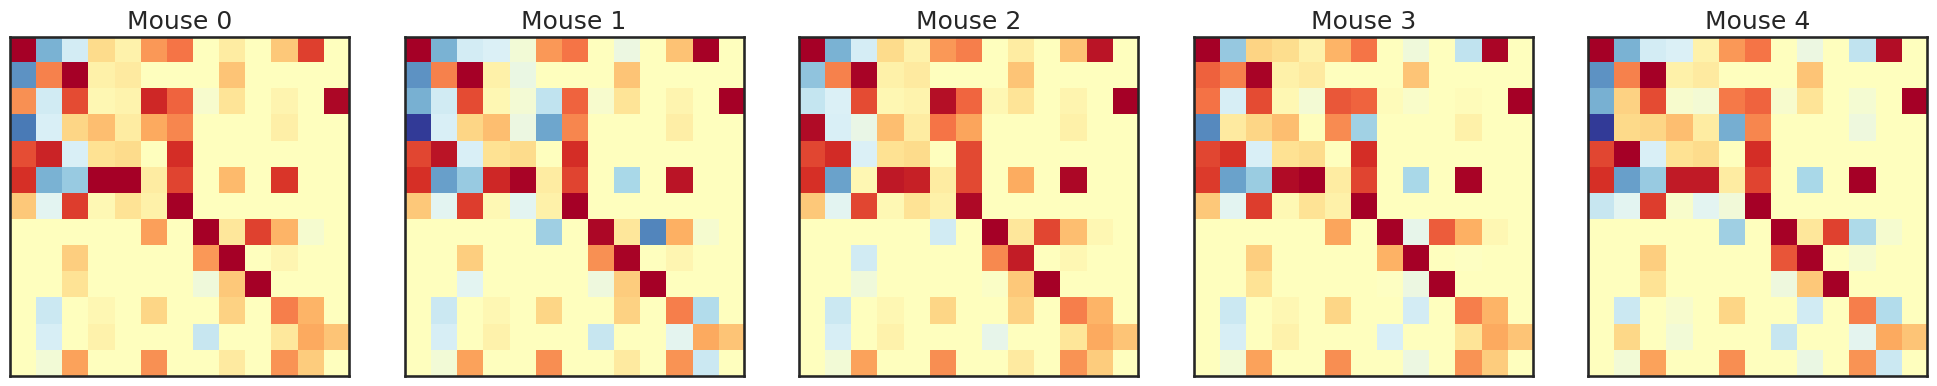

In [8]:
import numpy as np
import matplotlib.pyplot as plt

static_fc = {m: np.mean(data_dict[m], axis=0) for m in range(5)}

vmin, vmax = -1, 1

fig, axes = plt.subplots(1, 5, figsize=(20, 4))

for m in range(5):
    ax = axes[m]
    ax.imshow(static_fc[m], cmap="RdYlBu_r", vmin=vmin, vmax=vmax)
    ax.set_title(f"Mouse {m}")
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.savefig("five_mouse_static_fc.pdf", format="pdf")
plt.show()